In [1]:
!pip install --user torchvision
#pip install torch torchvision matplotlib requests pillow



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.


In [2]:
import torch
import torchvision.transforms as T
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

model = fasterrcnn_resnet50_fpn(pretrained=True)
model.eval()

def load_image(image_path):
    image = Image.open(image_path).convert("RGB")
    transform = T.Compose([T.ToTensor()])
    return transform(image).unsqueeze(0), image


e:\Z_Arise\rika_dl_env\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
e:\Z_Arise\rika_dl_env\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [3]:
def detect_and_show(image_path):
    image_tensor, original_image = load_image(image_path)

    with torch.no_grad():
        predictions = model(image_tensor)

    pred_boxes = predictions[0]['boxes'].cpu().numpy()
    pred_scores = predictions[0]['scores'].cpu().numpy()

    plt.figure(figsize=(10, 10))
    plt.imshow(original_image)

    for i, (box, score) in enumerate(zip(pred_boxes, pred_scores)):
        if score > 0.5:
            x1, y1, x2, y2 = box
            plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linewidth=2))
            plt.text(x1, y1, f'{score:.2f}', color='red', fontsize=12, weight='bold')

    plt.axis('off')
    plt.show()

In [4]:
# COCO dataset labels (91 classes, but model outputs 91 with background=0)
COCO_INSTANCE_CATEGORY_NAMES = [
    '__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign',
    'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack', 'umbrella',
    'N/A', 'N/A', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard',
    'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard',
    'surfboard', 'tennis racket', 'bottle', 'N/A', 'wine glass', 'cup', 'fork',
    'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange',
    'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch',
    'potted plant', 'bed', 'N/A', 'dining table', 'N/A', 'N/A', 'toilet',
    'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
    'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A', 'book',
    'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

def detect_and_show(image_path):
    image_tensor, original_image = load_image(image_path)

    with torch.no_grad():
        predictions = model(image_tensor)

    pred_boxes = predictions[0]['boxes'].cpu().numpy()
    pred_scores = predictions[0]['scores'].cpu().numpy()
    pred_classes = predictions[0]['labels'].cpu().numpy()  # <-- class labels

    plt.figure(figsize=(10, 10))
    plt.imshow(original_image)

    for i, (box, score, cls) in enumerate(zip(pred_boxes, pred_scores, pred_classes)):
        if score > 0.5:
            x1, y1, x2, y2 = box
            label = COCO_INSTANCE_CATEGORY_NAMES[cls]
            plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                              fill=False, edgecolor='red', linewidth=2))
            plt.text(x1, y1, f'{label}: {score:.2f}',
                     color='red', fontsize=12, weight='bold',
                     bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))

    plt.axis('off')
    plt.show()


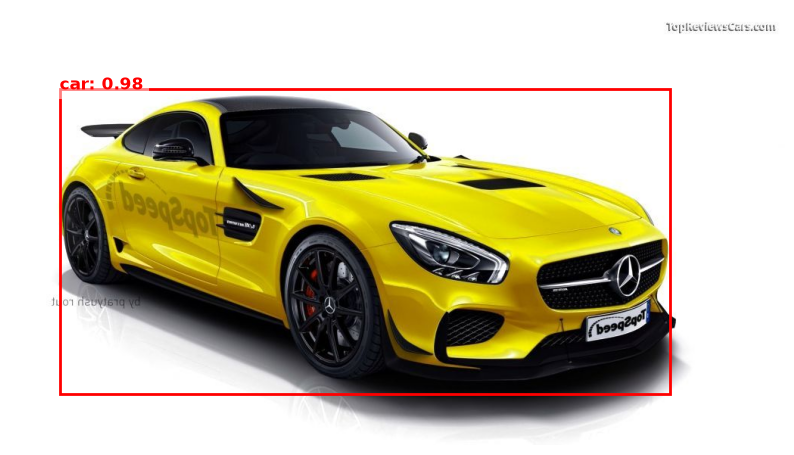

In [ ]:

# image_path = "/content/apple_4.jpg"
image_path = r'E:\Z_Arise\DL\Ex_3_Object_Detector_using_CNN\archive (7)\Images\Image_1.jpg'
detect_and_show(image_path)


e:\Z_Arise\rika_dl_env\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


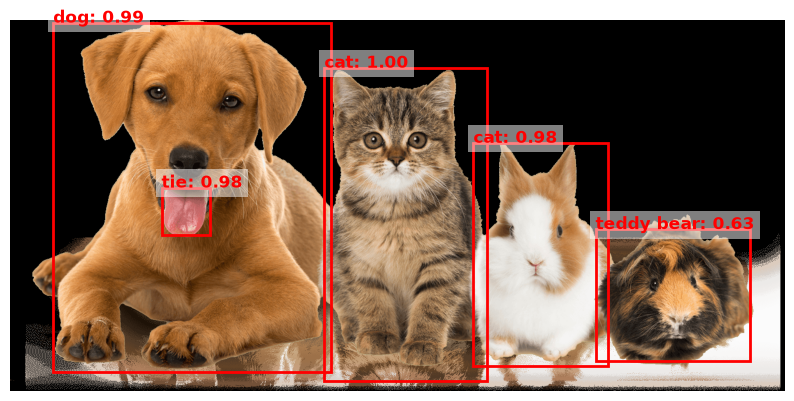

In [13]:
image_path = r"E:\Z_Arise\DL\Ex_3_Object_Detector_using_CNN\archive (7)\Images\Image_62.png"

detect_and_show(image_path)


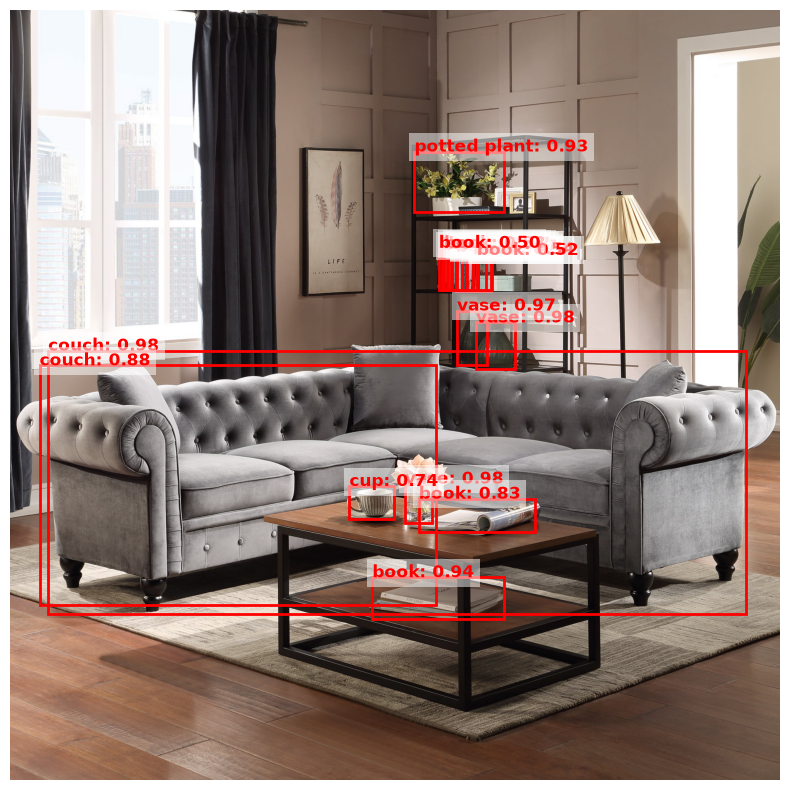

In [15]:
image_path = r"E:\Z_Arise\DL\Ex_3_Object_Detector_using_CNN\archive (7)\Images\Image_76.jpeg"

detect_and_show(image_path)


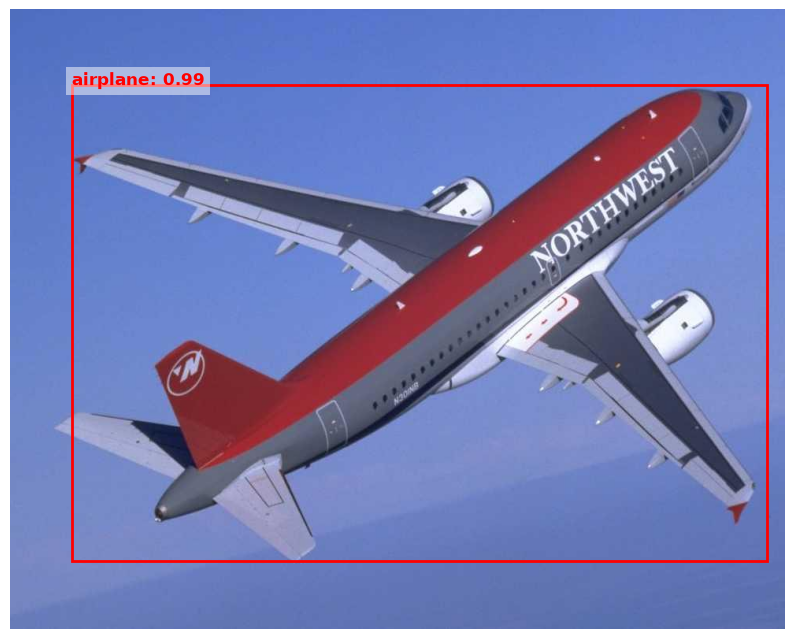

In [20]:
image_path = r"E:\Z_Arise\DL\Ex_3_Object_Detector_using_CNN\archive (7)\Images\Image_145.jpg"

detect_and_show(image_path)


Processing: Image_1.jpg


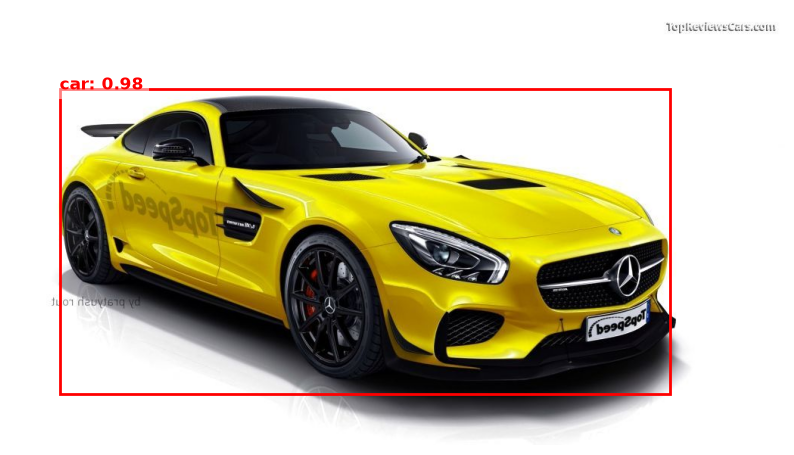

Processing: Image_10.jpg


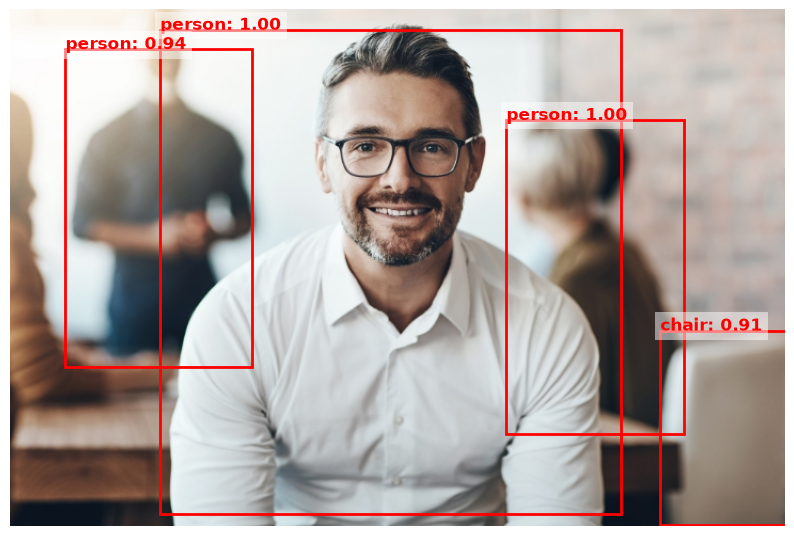

Processing: Image_100.jpg


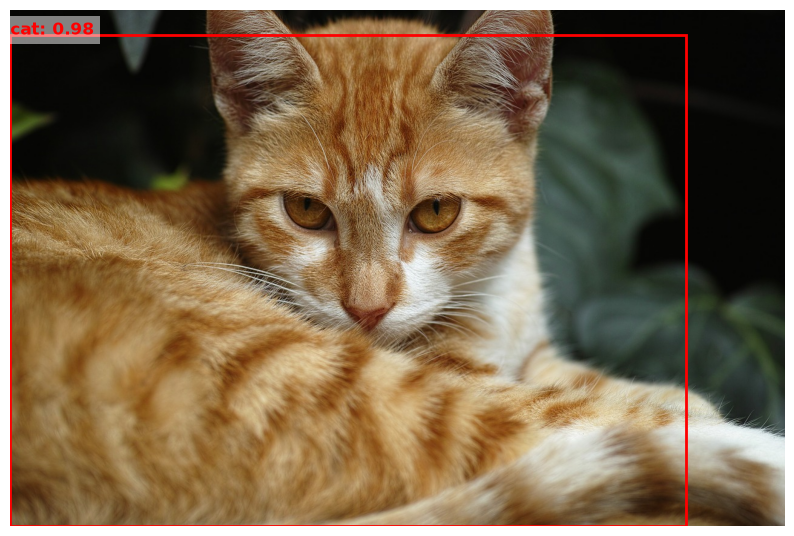

Processing: Image_101.jpeg


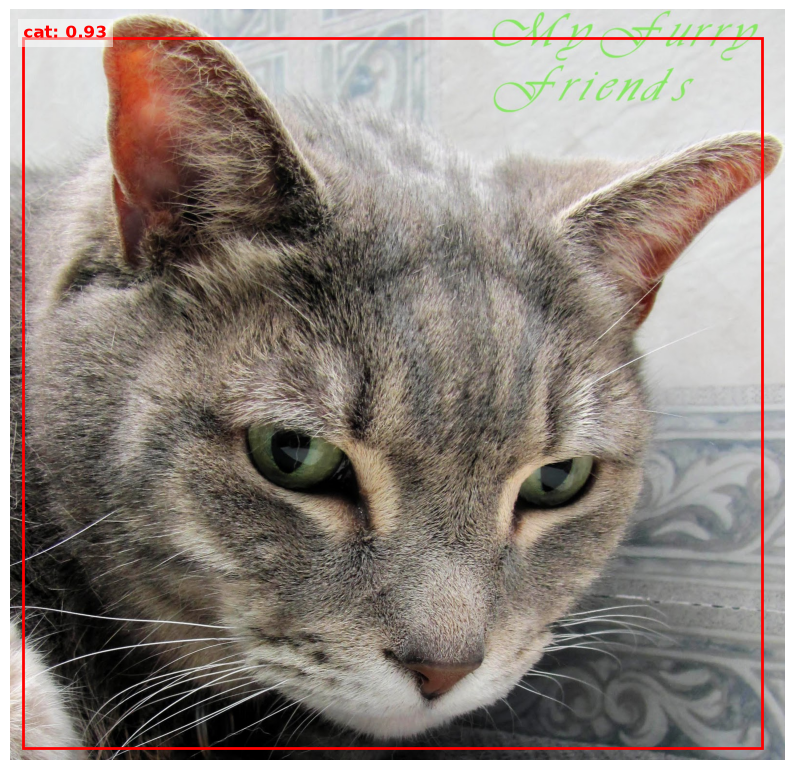

Processing: Image_102.jpg


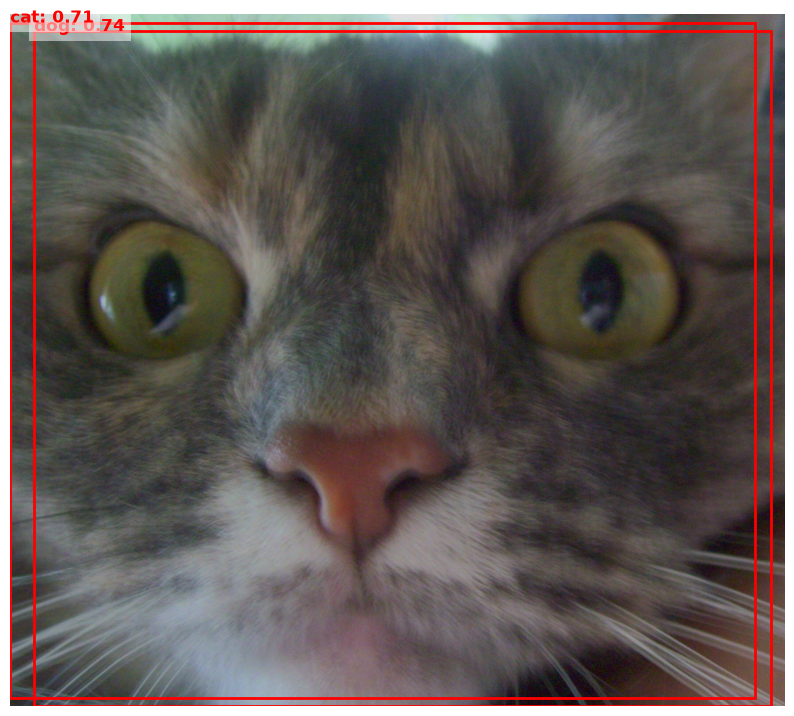

In [25]:
# TO detect every image 
import os

# Define the folder path
image_folder = r"E:\Z_Arise\DL\Ex_3_Object_Detector_using_CNN\archive (7)\Images"

# Get all image files from the folder (filter by common image extensions)
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
image_files = [f for f in os.listdir(image_folder) 
               if f.lower().endswith(image_extensions)]

# Loop through each image file
for image_file in image_files[:5]:
    image_path = os.path.join(image_folder, image_file)
    print(f"Processing: {image_file}")
    detect_and_show(image_path)

## To save the detectings in a output folder

In [26]:
import matplotlib.pyplot as plt

def detect_and_save(image_path, output_folder):
    # ... your detection code ...
    plt.savefig(os.path.join(output_folder, f"detected_{os.path.basename(image_path)}"))
    plt.close()

output_folder = r"E:\Z_Arise\DL\Ex_3_Object_Detector_using_CNN\output"
os.makedirs(output_folder, exist_ok=True)

for image_file in image_files:
    image_path = os.path.join(image_folder, image_file)
    detect_and_save(image_path, output_folder)